---
tags: [tutorial]
---

# QPEとリソース推定

量子位相推定（Quantum Phase Estimation、QPE）は、ユニタリ$U$の固有状態$|\psi\rangle$に対応する固有位相$\phi$を推定するアルゴリズムです。

$$
U|\psi\rangle=e^{2\pi i\phi}|\psi\rangle
$$

このノートブックでは、まずQPE回路を手作業で組み立て、Qamomileの標準ライブラリに含まれる`phase_estimation`と比較します。

## 1. QPEの仕組み

QPEでは、役割の異なる2つの量子レジスタを使います。

- **ターゲットレジスタ**は、$U$の固有状態$|\psi\rangle$を保持します。
- **カウント用レジスタ**は$n$個の量子ビットからなり、固有位相の$n$ビット近似を保持します。初期状態は$|0\rangle^{\otimes n}$です。

ターゲットからカウント用レジスタに固有位相を移す仕組みを、位相キックバックと呼びます。制御量子ビットを$|+\rangle$、ターゲットを$|\psi\rangle$に準備し、制御$U$を適用すると次の状態が得られます。

$$
\frac{|0\rangle|\psi\rangle+|1\rangle U|\psi\rangle}{\sqrt2}
=
\frac{|0\rangle+e^{2\pi i\phi}|1\rangle}{\sqrt2}|\psi\rangle
$$

ターゲットは元の固有状態に戻り、制御量子ビットには固有位相が相対位相として現れます。QPEではこの操作を$n$個の量子ビットに拡張し、次の3段階で位相を読み出します。

### 1. 一様な重ね合わせを準備する

$N=2^n$とします。ターゲットを$|\psi\rangle$に準備し、カウント用レジスタにアダマールゲートを適用します。これにより、$N$個の計算基底状態の一様な重ね合わせが得られます。

$$
|\Psi_1\rangle
=
\frac{1}{\sqrt N}
\sum_{y=0}^{N-1}|y\rangle|\psi\rangle.
$$

### 2. 制御付きのべき乗で位相を蓄積する

基底状態を$y=\sum_{k=0}^{n-1}y_k2^k$と表します。カウント用レジスタの$k$番目の量子ビットを制御として、ターゲットに$U^{2^k}$を適用します。その結果、次の状態が得られます。

$$
|\Psi_2\rangle
=
\frac{1}{\sqrt N}
\sum_{y=0}^{N-1}
e^{2\pi i\phi y}|y\rangle|\psi\rangle
$$

これで$\phi$の情報が振幅に記録されます。

### 3. 逆QFTで復号して測定する

$\phi=a/N$が$n$ビットで表現できる場合、カウント用レジスタは$\operatorname{QFT}_N|a\rangle$の状態になります。逆QFTを適用すると、次の状態が得られます。

$$
|\Psi_3\rangle=|a\rangle|\psi\rangle
$$

カウント用レジスタを測定すると整数$a$が得られ、位相の推定値は次のようになります。

$$
\widetilde{\phi}=\frac{a}{2^n}
$$

$\phi$を$n$ビットで正確に表現できない場合、測定結果は最も近い値の周辺に分布します。1ビット増やすと位相の分解能$2^{-n}$は半分になり、制御付きユニタリの最大のべき指数は2倍になります。

### このノートブックで使う例

位相を推定するユニタリとして、$\theta=3\pi/4$の位相ゲートを使います。このゲートは$P(\theta)|1\rangle=e^{i\theta}|1\rangle$を満たします。求める位相は$\phi=\theta/(2\pi)=3/8=0.011_2$です。この位相は3個の量子ビットで正確に表現できるため、QPEは計算基底状態$|011\rangle$を返すと予想されます。

:::{note}
一般の入力$|\chi\rangle=\sum_jc_j|\psi_j\rangle$には、複数の固有状態が含まれます。固有位相が互いに異なり、カウント用のビット数で正確に表現できる場合、カウント用レジスタを測定すると、確率$|c_j|^2$で$\phi_j$が得られ、ターゲットは$|\psi_j\rangle$に射影されます。このノートブックでは、既知の固有状態$|1\rangle$を使います。
:::

In [1]:
# Qamomileと、このノートブックで使うパッケージをインストールします。
# !pip install "qamomile[qiskit]" matplotlib

In [2]:
from __future__ import annotations

import math

import matplotlib.pyplot as plt

import qamomile as qm
from qamomile.stdlib import inverse_qft, phase_estimation

SHOTS = 512
THETA = 3.0 * math.pi / 4.0
EXPECTED_PHASE = 3.0 / 8.0


@qm.qkernel(kind="unitary")
def phase_gate(q: qm.Q[qm.Bits[1]], theta: qm.Real) -> qm.Q[qm.Bits[1]]:
    """Apply a phase of theta to the eigenstate |1⟩."""
    return qm.p(q, theta)

## 2. QPE回路を手作業で組み立てる

`phase_gate`は、$|1\rangle$の状態に角度`theta`の位相を加えます。次の変換を行います。

$$
P(\theta)|0\rangle=|0\rangle,\qquad
P(\theta)|1\rangle=e^{i\theta}|1\rangle
$$

ターゲットを$|1\rangle$に準備すると、固有値は$e^{i\theta}=e^{2\pi i\phi}$になります。したがって、QPEが返す位相は$\phi=\theta/(2\pi)$です。

以下の`manual_qpe`は、先ほどのQPEの手順をそのままコードにしたものです。

1. `qm.qubits(n)`でカウント用レジスタを、`qm.qubits(1)`でターゲットレジスタを確保します。
2. `qm.x`でターゲットレジスタを固有状態$|1\rangle$に準備し、アダマールゲートでカウント用レジスタを重ね合わせ状態にします。
3. 各カウント用量子ビットを制御として、`qm.control(phase_gate, counting, target, theta, at=k)`でユニタリを`2**k`回適用します。
4. `inverse_qft(counting, n)`で位相を復号し、レジスタのビット順を反転して`UFixed`として扱い、測定します。

`UFixed`は、量子レジスタを符号なし固定小数点数として扱うためのQamomileの型です。`integer_bits=0`では、$n$個の量子ビットすべてを小数部として解釈します。したがって、逆QFT後の整数$a$は位相$a/2^n$として読み出されます。

In [3]:
@qm.qkernel
def manual_qpe(
    n: qm.Const[qm.Int], theta: qm.Const[qm.Real]
) -> qm.Shot[qm.UFixed[0, n]]:  # noqa: F821
    """Build QPE from Hadamards, controlled powers, and an inverse QFT."""
    counting = qm.qubits(n)
    target = qm.x(qm.qubits(1))
    for k in range(n):
        counting = qm.h(counting, target=k)

    system = (counting, target)
    for k in range(n):
        for _ in range(2**k):
            counting, target = system
            counting, target = qm.control(phase_gate, counting, target, theta, at=k)
            system = (counting, target)

    counting, target = system
    counting = inverse_qft(counting, n)
    for left in range(n // 2):
        counting = qm.swap(counting, left=left, right=n - left - 1)
    phase = qm.as_fixed(counting, integer_bits=0)
    phase_value = qm.measure(phase)
    _target_value = qm.measure(target)
    return phase_value

`qm.control(...)`は、既存のqkernelを制御付きユニタリとして適用します。このため、QPE用にユニタリ自体を書き換える必要はありません。

`2**k`回繰り返すことで、制御付きの$U^{2^k}$を実現します。

最後の`inverse_qft(counting, n)`で、位相のパターンを整数$a$に変換します。`UFixed`では最上位ビットを先頭に置くため、スワップでビット順を反転します。続く`qm.as_fixed(counting, integer_bits=0)`は、同じ量子レジスタを固定小数点数$a/2^n$として解釈します。例えば、$|011\rangle$の場合は次のようになります。

$$
\frac{1\cdot2^0+1\cdot2^1+0\cdot2^2}{2^3}
=\frac38
$$

`as_fixed`はゲートを追加せずにレジスタを`UFixed`として扱います。測定すると位相の数値が得られます。残っているターゲットも測定して消費します。

In [4]:
endpoint = qm.qiskit.Aer()
manual_program = qm.specialize(manual_qpe, n=3, theta=THETA)
manual_executable = qm.compile(manual_program, to=endpoint.target)
manual_result = qm.run(manual_executable, on=endpoint, shots=SHOTS, seed=42).result
print("Manual QPE:", dict(manual_result.values))

assert len(manual_result.values) == 1
((manual_phase, manual_count),) = manual_result.values.items()
assert manual_count == SHOTS
assert math.isclose(manual_phase, EXPECTED_PHASE, abs_tol=1e-12)

Manual QPE: {0.375: 512}


$\phi=3/8$は3ビットで正確に表現できるため、ノイズのないシミュレータではすべてのショットで同じ位相が得られます。一般の位相では近い値が複数現れるため、`result.values`は測定値とその出現回数の分布として読み取ります。

## 3. 組み込みの`phase_estimation`

Qamomileは同じ手順を`phase_estimation`として提供しています。QPEを手作業で組み立てると、回路の構造を学びやすくなります。より複雑なアルゴリズムを組み立てる場合は、標準ライブラリに含まれるアルゴリズムを使うことで実装を簡潔にできます。

`phase_estimation`は、次の引数を取ります。

- `unitary`：位相の推定対象となるユニタリqkernel。この例では`example_phase_gate`です。
- `target`：固有状態に準備したターゲットレジスタ。
- `precision`：カウント用レジスタの量子ビット数。この例では`n`です。

`phase_estimation`に渡すゲートは、量子引数を1つ取ります。`example_phase_gate`で`theta`を固定してから渡します。
この関数はカウント用レジスタを準備し、位相と保持されたターゲットレジスタを返します。

手作業で組み立てた実装では`qm.as_fixed(..., integer_bits=0)`を明示的に呼び出しましたが、`phase_estimation`にはこの変換が含まれます。どちらの実装でも、`measure(phase)`は$a/2^n$に復号された数値を返します。

In [5]:
@qm.qkernel(kind="unitary")
def example_phase_gate(q: qm.Q[qm.Bits[1]]) -> qm.Q[qm.Bits[1]]:
    return phase_gate(q, THETA)


@qm.qkernel
def measure_phase(
    unitary: qm.QKernel[qm.Q[qm.Bits[1]], qm.Q[qm.Bits[1]]],
    n: qm.Const[qm.Int],
) -> qm.Shot[qm.UFixed[0, n]]:  # noqa: F821
    """Measure the phase of a single-qubit unitary with the standard library."""
    target = qm.x(qm.qubits(1))
    phase, target = phase_estimation(unitary, target, n)
    phase_value = qm.measure(phase)
    _target_value = qm.measure(target)
    return phase_value


@qm.qkernel
def builtin_qpe(n: qm.Const[qm.Int]) -> qm.Shot[qm.UFixed[0, n]]:  # noqa: F821
    return measure_phase(example_phase_gate, n)

In [6]:
builtin_program = qm.specialize(builtin_qpe, n=3)
builtin_executable = qm.compile(builtin_program, to=endpoint.target)
builtin_result = qm.run(builtin_executable, on=endpoint, shots=SHOTS, seed=42).result
print("Built-in QPE:", dict(builtin_result.values))

assert len(builtin_result.values) == 1
((builtin_phase, builtin_count),) = builtin_result.values.items()
assert math.isclose(builtin_phase, EXPECTED_PHASE, abs_tol=1e-12)
assert builtin_count == SHOTS

Built-in QPE: {0.375: 512}


## 4. 具体的な回路の論理リソースを数える

`qm.resources.logical()`は、qkernelを実行せずにQamomileのIR（中間表現）を解析します。同じ3ビットの問題で、手作業で組み立てた実装と組み込みの実装を比較します。それぞれの推定結果は下限と上限の組で表します。ゲート数の上限が`None`の場合は、制御付き位相の呼び出しに対する上限を解析で求められなかったことを示します。どちらの実装も同じ上下限を返しますが、コンパイル後の回路は異なる場合があります。

In [7]:
manual_resources = qm.resources.logical(manual_program)
builtin_resources = qm.resources.logical(builtin_program)

metrics = {
    "qubits": qm.resources.LOGICAL_PEAK_QUBITS,
    "gates": qm.resources.LOGICAL_GATES,
    "two-qubit": qm.resources.LOGICAL_TWO_QUBIT_GATES,
}
manual_bounds = {
    name: manual_resources.metric(metric).numeric_enclosure()
    for name, metric in metrics.items()
}
builtin_bounds = {
    name: builtin_resources.metric(metric).numeric_enclosure()
    for name, metric in metrics.items()
}
print("Manual bounds:", manual_bounds)
print("Built-in bounds:", builtin_bounds)

assert manual_bounds["qubits"] == builtin_bounds["qubits"] == (4, 4)
assert manual_bounds == builtin_bounds

Manual bounds: {'qubits': (4, 4), 'gates': (19, None), 'two-qubit': (5, None)}
Built-in bounds: {'qubits': (4, 4), 'gates': (19, None), 'two-qubit': (5, None)}


## 5. 組み込みのQPEに可変幅のオラクルを渡す

ここまでは具体的な位相ゲートを実行し、その回路からリソースを数えました。ハミルトニアンシミュレーションなどのサブルーチンを実装する前に、QPE全体のリソースが入力の大きさに応じてどう変わるかを調べたい場合もあります。実装がないユニタリは、名前とシグネチャだけを持つqkernelで表現できます。

ここでは、2つの変数の役割を区別します。

- $n$：ユニタリ$U$が作用するターゲットレジスタの量子ビット数。
- $m$：位相を$m$ビットで推定するカウント用レジスタの量子ビット数。

In [8]:
@qm.qkernel(kind="unitary")
def u(target: qm.Q[qm.Bits[n]]) -> qm.Q[qm.Bits[n]]: ...  # noqa: F821

シグネチャでは、レジスタの幅を`n`という変数で表しています。これにより、異なる量子ビット数$n$で同じオラクルを再利用できます。

In [9]:
@qm.qkernel
def qpe_model(
    n: qm.Const[qm.Int],
    m: qm.Const[qm.Int],
) -> tuple[qm.Q[qm.UFixed[0, m]], qm.Q[qm.Bits[n]]]:  # noqa: F821
    """Build a symbolic resource model of QPE with a variable-width oracle."""
    target = qm.qubits(n)

    # 実際のQPEでは、ここでターゲットをUの固有状態に準備します。
    return phase_estimation(u, target, m)

`qm.resources.logical()`に具体的な入力を渡さないため、結果は$n$と$m$を使った式になります。この例では、量子ビット数は$m+n$です。

また、`phase_estimation`はカウント用レジスタの$k$番目の量子ビットを制御として、制御付きの$U^{2^k}$を呼び出します。$U^{2^k}$を元のオラクル$U$への$2^k$回の問い合わせとして数えるモデルでは、問い合わせ回数は次のようになります。

$$
1+2+\cdots+2^{m-1}=2^m-1
$$

Qamomileは、ゲートコストが不明な場合でも、オラクルの呼び出し回数と問い合わせ回数を名前にひも付けて記録します。

オラクルのコストがわからないと全体のゲート数は確定しないため、ここでは量子ビット数と問い合わせ回数の推定結果を示します。実行用にコンパイルするには、オラクルの実装が必要です。

In [10]:
symbolic_resources = qm.resources.logical(qpe_model)
qubit_metric = qm.resources.LOGICAL_PEAK_QUBITS
query_metric = qm.resources.algorithmic_query_count(u.symbol)

print("Symbolic Oracle queries:", symbolic_resources.metric(query_metric))

Symbolic Oracle queries: = bounded_sum(0, m + -1, power(2, control_index)) queries


最後に、量子ビット数と問い合わせ回数を表す式に値を代入して、具体的な数値を求めます。式への代入だけで済むため、回路を構築せずに短時間で計算できます。

In [11]:
for n_value, m_value in [(2, 3), (4, 3), (4, 5)]:
    concrete = symbolic_resources.evaluate(n=n_value, m=m_value)
    qubits = concrete.metric(qubit_metric).numeric_enclosure()
    queries = concrete.metric(query_metric).numeric_enclosure()
    print(f"n={n_value}, m={m_value}: qubits={qubits[0]}, queries={queries[0]}")
    assert qubits == (n_value + m_value, n_value + m_value)
    assert queries == (2**m_value - 1, 2**m_value - 1)

n=2, m=3: qubits=5, queries=7
n=4, m=3: qubits=7, queries=7
n=4, m=5: qubits=9, queries=31


## 演習：3ビットで表現できない位相

この演習では、$\phi=1/3$に対応する角度`2*pi/3`を使います。この位相は3ビットで正確に表現できないため、測定結果が複数現れます。カウント用レジスタのビット数を増やすと位相の分解能$2^{-n}$が細かくなるので、分布のピークが$1/3$に近づくことを確認します。

具体的には、次の2点を調べます。

1. カウント用レジスタが3ビットの場合と5ビットの場合で位相の分布を比較します。
2. カウント用レジスタのビット数を2から6まで増やし、最も頻繁に現れる値と$1/3$の誤差が小さくなることを確認します。

In [12]:
# TODO: theta=2*pi/3で、位相分布とカウント用ビット数に応じた誤差の変化を調べます。

### 解答例

counting bits=2: peak=0.25000, error=0.08333


counting bits=3: peak=0.37500, error=0.04167


counting bits=4: peak=0.31250, error=0.02083


counting bits=5: peak=0.34375, error=0.01042


counting bits=6: peak=0.32812, error=0.00521


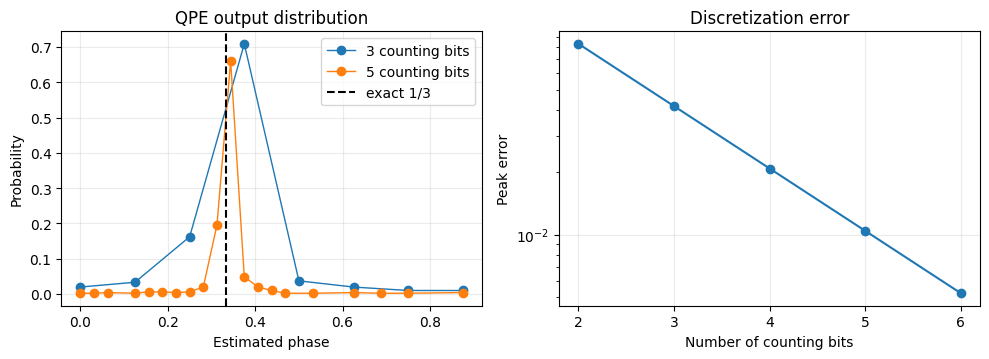

In [13]:
exercise_phase = 1.0 / 3.0
exercise_theta = 2.0 * math.pi * exercise_phase
counting_widths = [2, 3, 4, 5, 6]
phase_distributions = {}
peak_errors = {}


@qm.qkernel(kind="unitary")
def exercise_phase_gate(q: qm.Q[qm.Bits[1]]) -> qm.Q[qm.Bits[1]]:
    return phase_gate(q, exercise_theta)


@qm.qkernel
def exercise_qpe(n: qm.Const[qm.Int]) -> qm.Shot[qm.UFixed[0, n]]:  # noqa: F821
    return measure_phase(exercise_phase_gate, n)


for counting_bits in counting_widths:
    exercise_program = qm.specialize(exercise_qpe, n=counting_bits)
    exercise_executable = qm.compile(exercise_program, to=endpoint.target)
    exercise_result = qm.run(
        exercise_executable, on=endpoint, shots=SHOTS, seed=42
    ).result
    phase_distributions[counting_bits] = sorted(exercise_result.values.items())

    peak_phase, _ = max(exercise_result.values.items(), key=lambda item: item[1])
    peak_errors[counting_bits] = abs(peak_phase - exercise_phase)
    print(
        f"counting bits={counting_bits}: "
        f"peak={peak_phase:.5f}, error={peak_errors[counting_bits]:.5f}"
    )

assert all(
    peak_errors[right] < peak_errors[left]
    for left, right in zip(counting_widths, counting_widths[1:], strict=False)
)

fig, axes = plt.subplots(1, 2, figsize=(10, 3.7))

for counting_bits in [3, 5]:
    distribution = phase_distributions[counting_bits]
    phases = [phase for phase, _ in distribution]
    probabilities = [count / SHOTS for _, count in distribution]
    axes[0].plot(
        phases,
        probabilities,
        marker="o",
        linewidth=1,
        label=f"{counting_bits} counting bits",
    )

axes[0].axvline(exercise_phase, color="black", linestyle="--", label="exact 1/3")
axes[0].set(
    xlabel="Estimated phase",
    ylabel="Probability",
    title="QPE output distribution",
)
axes[0].legend()
axes[0].grid(alpha=0.25)

axes[1].plot(
    counting_widths,
    [peak_errors[width] for width in counting_widths],
    marker="o",
)
axes[1].set(
    xlabel="Number of counting bits",
    ylabel="Peak error",
    title="Discretization error",
    yscale="log",
)
axes[1].set_xticks(counting_widths)
axes[1].grid(alpha=0.25)

plt.tight_layout()
plt.show()

## まとめ

- QPEでは、ターゲットを固有状態、または固有状態との重なりが大きい状態に準備します。カウント用レジスタにはアダマールゲートを適用し、ターゲットに作用する$U$のべき乗を制御した後、逆QFTを適用します。
- Qamomileの標準ライブラリは、QPEを含む複数のアルゴリズムを提供しています。
- 同じqkernelを使って、実行可能な回路を構築することも、リソースを推定することもできます。
- 未実装のサブルーチンをユニタリqkernelで表し、実装を仮定せずにオラクルの問い合わせ回数を式で推定できます。